# Ducks in Virginia: three species, three seasonal stories

**What changes when you look beyond a dot on a bird map?**

Virginia's modeled duck calendar contains striking contrasts: Bufflehead is
concentrated in the cold months, Blue-winged Teal has spring and fall pulses,
and Wood Duck remains present in the model through summer. Start with their
photographs, follow their annual curves, then connect observation locations
to named lakes and bays.

This notebook combines real **2024–2025 observation records**, a **2023 seasonal
abundance model**, and Overture's geographic features. Each answers a different
question: what was reported, how a modeled annual cycle varies, and what mapped
water lies nearby.


## Meet the ducks behind the annual curves

| **Wood Duck** | **Bufflehead** | **Blue-winged Teal** |
| --- | --- | --- |
| 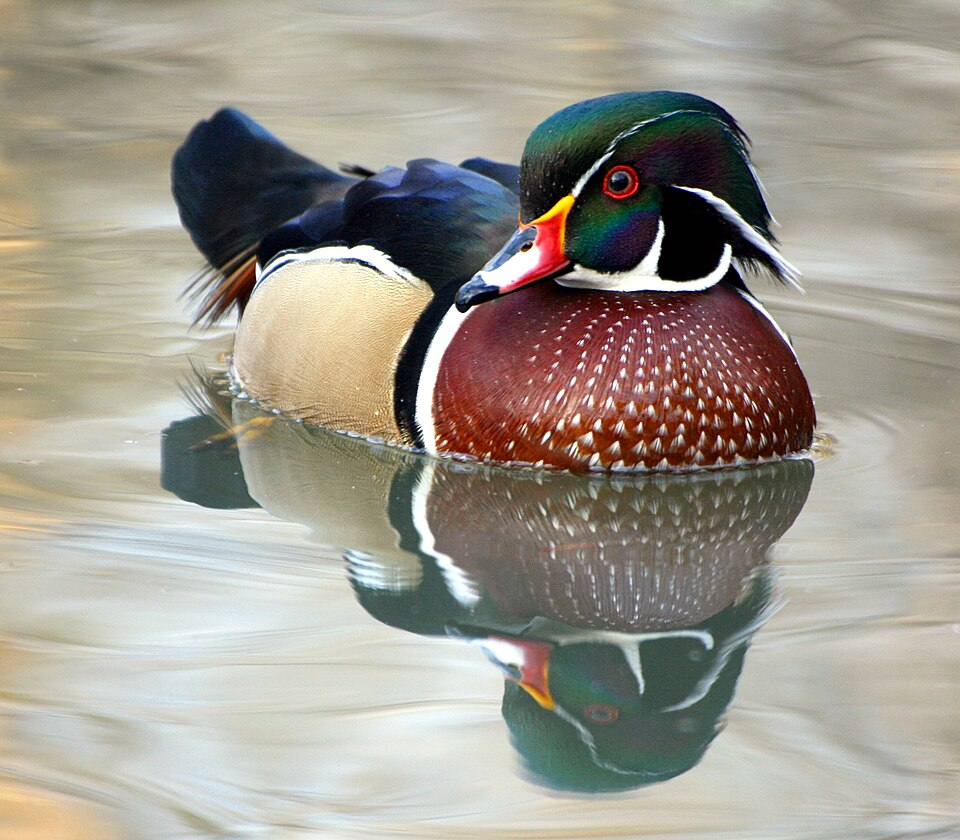 | 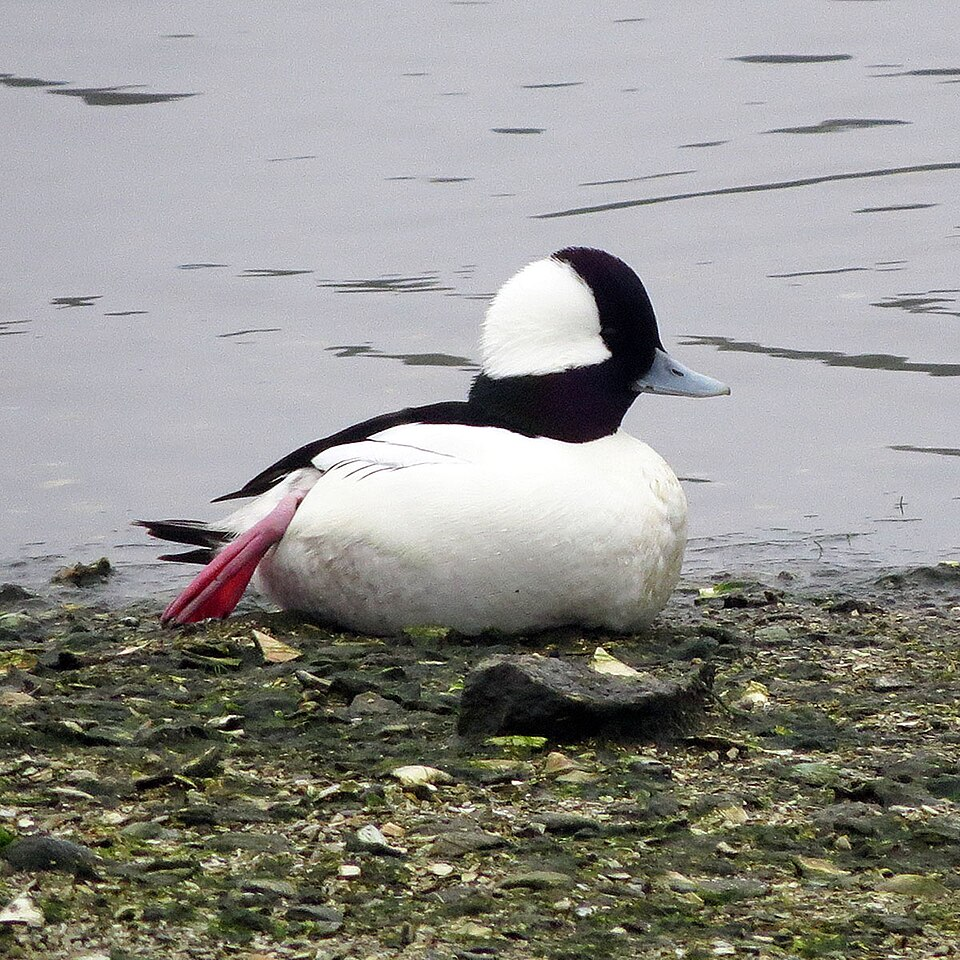 | 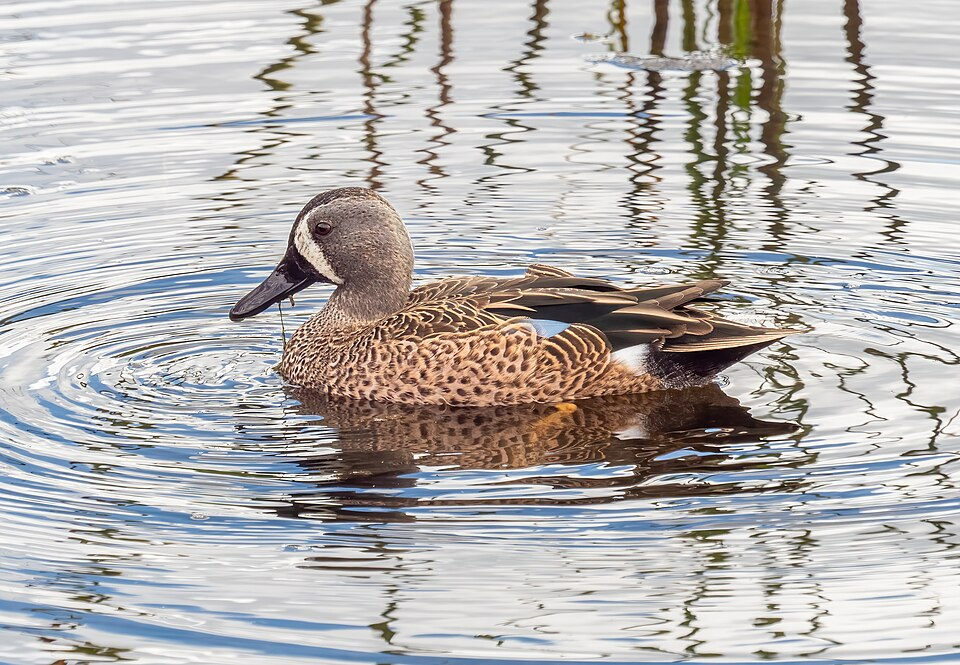 |
| *Aix sponsa* | *Bucephala albeola* | *Spatula discors* |
| **A broad annual presence.** The Virginia model stays above zero through summer, with its largest peak in March. | **A winter concentration.** Modeled abundance drops close to zero in summer and climbs sharply late in the year. | **Two seasonal pulses.** The Virginia model rises in spring and again in fall. |
| Photo: [law keven](https://commons.wikimedia.org/wiki/File:Aix_sponsa_male.jpg) · [CC BY-SA 2.0](https://creativecommons.org/licenses/by-sa/2.0) | Photo: [Don Faulkner](https://commons.wikimedia.org/wiki/File:Bufflehead_(male)_(16255698348).jpg) · [CC BY-SA 2.0](https://creativecommons.org/licenses/by-sa/2.0) | Photo: [Rhododendrites](https://commons.wikimedia.org/wiki/File:Blue-winged_teal_(94829).jpg) · [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0) |

Species portraits, not photographs of the analyzed Virginia records. These images show males; females and nonbreeding plumage can look different. [Photo sources and reuse licenses](images/species/README.md).


### Three findings to follow

- **Different ducks, different calendars.** The curves reveal a winter concentration, a broad annual presence, and two seasonal pulses within the same state. The dates describe the 2023 model; they are not arrival forecasts.
- **A diverse observation snapshot.** The spatially filtered dataset contains **580 records across 29 duck species**. Mallard leads with 168 records, but Hooded Merganser contributes 71 and Wood Duck 47.
- **A named place emerges from the join.** In this saved run, **Burke Lake has 38 nearby records covering 14 duck species** within 500 m of its mapped water geometry. This is a result of joining coordinates to water polygons, not a claim about access or bird numbers.

The useful connection is **species → season → place**. Two TypeScript workers
make it queryable in one DuckDB session:
[vgi-ducks](https://github.com/Query-farm/vgi-ducks) supplies taxonomy, seasonal
ranges, and weekly abundance; the
[Overture worker](https://github.com/Query-farm/vgi-overture-maps-typescript)
supplies Virginia's boundary and water polygons. Public iNaturalist records via
GBIF supply the observation coordinates.


## Run this source notebook

Setup and plotting code are collapsed in Jupyter. The [reader edition](spatial-migration.ipynb)
omits setup completely and keeps the analytical SQL, tables, and figures.

Configure your own [Status and Trends key](https://ebird.org/st/request) as
`EBIRDST_KEY` in the launching environment; never paste it into a notebook cell.
This is separate from the recent-sightings `EBIRD_API_KEY`.
From the `vgi-ducks` checkout, run `make notebook`. It uses Python 3.12 and the pinned
notebook dependencies. The Overture checkout is expected beside this repository at
`../vgi-overture-maps-typescript`; run `bun install --frozen-lockfile` there once.
Override its location with `VGI_OVERTURE_REPO` if needed. The notebook runs the local
Overture worker and pins its data release to **2026-10-21.0**.

For interactive use:

```sh
uv run --no-project --python 3.12 --with-requirements notebooks/requirements.txt jupyter lab notebooks/virginia-ducks.source.ipynb
```

Choose Python 3, restart the kernel, and run all cells. `VGI_NOTEBOOK_REFRESH=1 make
notebook` refreshes the local GBIF cache. Overture retains only recent releases;
if this release retires, update the Overture checkout and the release setting
below together, then regenerate the figures. Internet access is required.


In [1]:
import json, os, shlex, shutil, subprocess, tempfile
from pathlib import Path
from datetime import datetime
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import create_engine
from IPython.display import display

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
notebook_dir = Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"
project_dir = notebook_dir.parent
import sys
sys.path.insert(0, str(notebook_dir))
from virginia_support import observation_snapshot, configure_plots, draw_geometry, save_chart
assert duckdb.__version__ == "2.0.0", "Use the pinned notebook requirements."
for key in ("DUCKS_EBIRD_BASE_URL", "DUCKS_STATUS_BASE_URL", "DUCKS_STATUS_SAMPLE_BASE_URL"):
    assert not os.environ.get(key), "Unset fixture endpoint overrides before running this notebook."

assert os.environ.get("EBIRDST_KEY", "").strip(), "Set EBIRDST_KEY in the environment before running. Never put it in a notebook cell."

OVERTURE_RELEASE = "2026-10-21.0"
overture_repo = Path(os.environ.get("VGI_OVERTURE_REPO", project_dir.parent / "vgi-overture-maps-typescript")).expanduser().resolve()
worker = overture_repo / "src/bin/worker.ts"
assert worker.exists(), "Clone Query-farm/vgi-overture-maps-typescript beside this repository, or set VGI_OVERTURE_REPO."
assert (overture_repo / "node_modules").is_dir(), "Run bun install --frozen-lockfile in the Overture checkout."
bun = shutil.which("bun")
assert bun, "Bun is needed to launch the local Overture TypeScript worker."
os.environ["OVERTURE_RELEASE"] = OVERTURE_RELEASE
overture_commit = subprocess.check_output(["git", "-C", str(overture_repo), "rev-parse", "HEAD"], text=True).strip()
records_path, observation_manifest = observation_snapshot(project_dir / ".cache/virginia-ducks")

extension_directory = tempfile.TemporaryDirectory(prefix="vgi-virginia-")
engine = create_engine("duckdb:///:memory:", connect_args={"config": {
    "extension_repository_directory": str(Path(extension_directory.name) / "repositories"),
    "extension_directory": str(Path(extension_directory.name) / "extensions"),
}})
%load_ext sql
%sql engine --alias virginia_demo
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = 0
%config SqlMagic.displaycon = False
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
configure_plots()
TEAL, GOLD, SLATE = "#087f8c", "#bc7d16", "#334155"


In [2]:
%%sql
SET allow_extension_repositories = 'allowed';
CREATE EXTENSION REPOSITORY IF NOT EXISTS query_farm
  WITH PREFIX 'https://duckdb-extensions.query.farm';
INSTALL vgi FROM query_farm; LOAD vgi FROM query_farm;
INSTALL spatial FROM core; LOAD spatial;
INSTALL httpfs FROM core; LOAD httpfs;
INSTALL icu FROM core; LOAD icu;
SET TimeZone = 'UTC';
SET geometry_always_xy = true;
SET s3_region = 'us-west-2';
ATTACH 'ducks' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-ducks@v0.1.0');


,Success


In [3]:
# Execute connection setup on the same SQLAlchemy connection used by %%sql.
from sql.connection import ConnectionManager
session = ConnectionManager.current.connection_sqlalchemy
quote = lambda text: "'" + str(text).replace("'", "''") + "'"
location = shlex.join([bun, "run", str(worker)])
session.exec_driver_sql(f"ATTACH 'overture' (TYPE vgi, LOCATION {quote(location)})")
session.exec_driver_sql(f"SET VARIABLE observations_file = {quote(records_path)}")
session.commit()


## 1. Use Virginia's boundary, not just a rectangular search

A record labeled “Virginia” can lie across a state line or in neighboring waters.
We retrieve both the land and territorial versions of Virginia from Overture,
then keep duck coordinates covered by its **territorial** boundary. The land
polygon gives the maps a coastline.

The four bounding-box predicates below constrain the Overture scan. Its catalog
enforces them before DuckDB reads the GeoParquet data.


In [4]:
%%sql
CREATE TEMP TABLE virginia AS
SELECT id, names.primary AS name, is_land, is_territorial, geometry
FROM overture.divisions.division_area
WHERE bbox.xmin BETWEEN -84 AND -75 AND bbox.xmax BETWEEN -84 AND -75
  AND bbox.ymin BETWEEN 36 AND 40 AND bbox.ymax BETWEEN 36 AND 40
  AND subtype = 'region' AND country = 'US' AND region = 'US-VA';

SELECT name, is_land, is_territorial,
       round(ST_Area_Spheroid(geometry) / 1000000) AS area_km2
FROM virginia ORDER BY is_territorial DESC;


,name,is_land,is_territorial,area_km2
0,Virginia,False,True,110757.0
1,Virginia,True,False,104738.0


The input is restricted to one source dataset, human observations marked present,
2024–2025 dates, known coordinate uncertainty of **250 m or less**, no GBIF-flagged
geospatial issue, and record licenses CC0 or CC BY. These filters create a selected
public-record dataset; they do not establish complete coverage of Virginia.

The SQL join below uses the worker's extant duck catalog to exclude geese, swans,
and names that do not match. GBIF's accepted species names are matched exactly;
there is no guessed mapping between taxonomies. A second spatial filter removes
coordinates outside the state.


In [5]:
%%sql
CREATE TEMP TABLE input_records AS
SELECT * FROM read_json(getvariable('observations_file'));

CREATE TEMP TABLE matched_ducks AS
SELECT r.*, s.common_name, s.species_code,
       ST_Point(r.longitude, r.latitude) AS point
FROM input_records AS r
JOIN ducks.main.species AS s
  ON r.scientific_name = s.scientific_name AND NOT s.extinct
WHERE try_cast(r.observation_date AS DATE) IS NOT NULL;

CREATE TEMP TABLE virginia_ducks AS
SELECT r.* FROM matched_ducks AS r
WHERE EXISTS (
  SELECT 1 FROM virginia AS v
  WHERE v.is_territorial AND ST_Covers(v.geometry, r.point)
);

SELECT (SELECT count(*) FROM input_records) AS eligible_waterfowl_records,
       (SELECT count(*) FROM matched_ducks) AS duck_catalog_matches,
       count(*) AS duck_records_inside_virginia,
       count(DISTINCT species_code) AS duck_species
FROM virginia_ducks;


,eligible_waterfowl_records,duck_catalog_matches,duck_records_inside_virginia,duck_species
0,800,582,580,29


In [6]:
%%sql points <<
SELECT gbif_id, common_name, scientific_name, species_code, longitude, latitude,
       observation_year, observation_month, uncertainty_m
FROM virginia_ducks ORDER BY gbif_id;


In [7]:
%%sql boundary_shapes <<
SELECT is_land, is_territorial,
       ST_AsGeoJSON(ST_SimplifyPreserveTopology(geometry, 0.001)) AS geometry_json
FROM virginia ORDER BY is_territorial DESC;


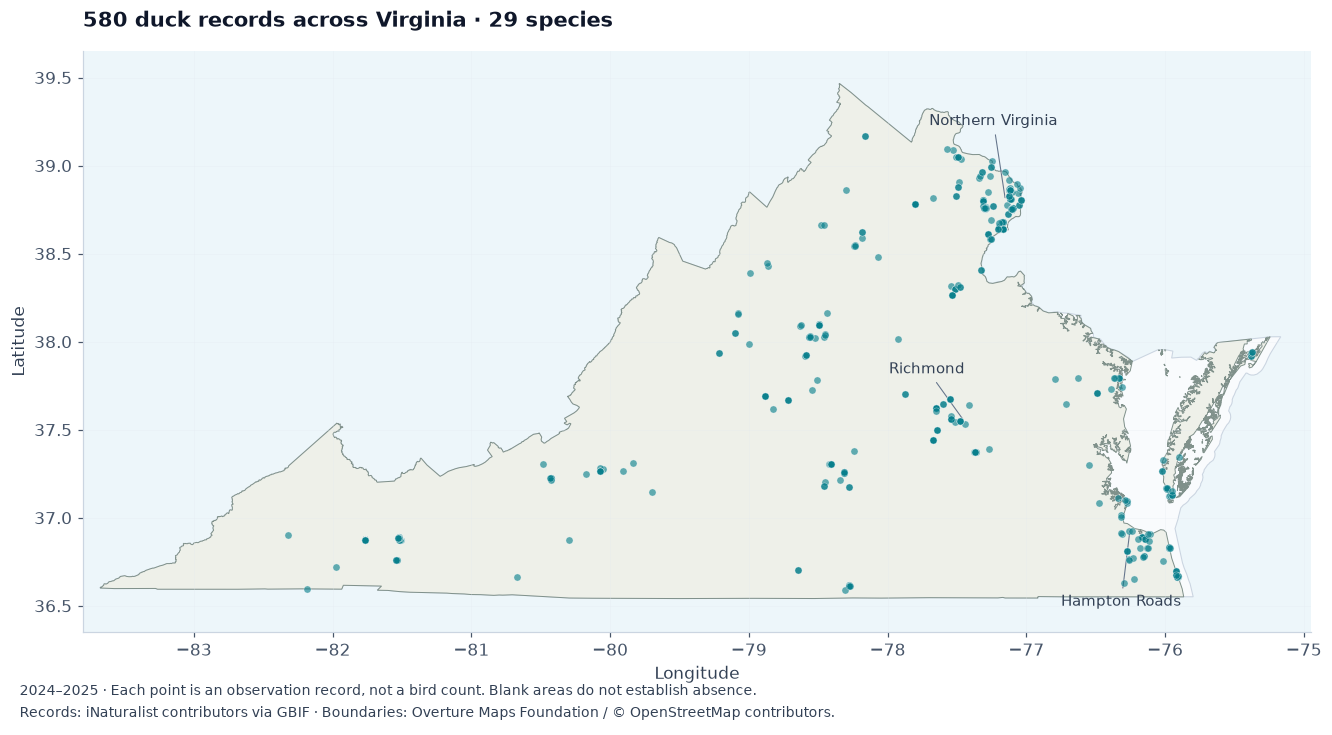

In [8]:
fig, ax = plt.subplots(figsize=(12, 6.5), layout="constrained")
land = boundary_shapes.loc[boundary_shapes.is_land].iloc[0].geometry_json
territory = boundary_shapes.loc[boundary_shapes.is_territorial].iloc[0].geometry_json
ax.set_facecolor("#edf6fa")
draw_geometry(ax, territory, "#f9fbfd", "#cbd5e1", linewidth=0.7)
draw_geometry(ax, land, "#eef0e9", "#80918b", linewidth=0.65)
ax.scatter(points.longitude, points.latitude, s=22, color=TEAL, alpha=0.62,
           linewidth=0.3, edgecolor="white", zorder=5)
for label, x, y, dx, dy in [
    ("Northern Virginia",-77.15,38.8,-0.55,0.43),
    ("Richmond",-77.44,37.54,-0.55,0.28),
    ("Hampton Roads",-76.25,36.95,-0.5,-0.45),
]:
    ax.annotate(label, (x,y), xytext=(x+dx,y+dy), fontsize=10, color=SLATE,
                arrowprops={"arrowstyle":"-","color":"#64748b","lw":0.7})
ax.set_xlim(-83.8,-74.95); ax.set_ylim(36.35,39.65)
ax.set_aspect(1/np.cos(np.deg2rad(38)))
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title(f"{len(points):,} duck records across Virginia · {points.species_code.nunique()} species",
             loc="left", weight="bold", pad=16)
ax.grid(alpha=0.3, linewidth=0.5)
fig.text(0.01,-0.025,"2024–2025 · Each point is an observation record, not a bird count. Blank areas do not establish absence.\n"
         "Records: iNaturalist contributors via GBIF · Boundaries: Overture Maps Foundation / © OpenStreetMap contributors.",
         fontsize=9,color=SLATE,linespacing=1.6)
save_chart(fig,"virginia-duck-records.png",notebook_dir)


## 2. Which ducks appear in these records?

The ranking describes **retained observation records in this source**, not which
species is most abundant in Virginia. Birders' locations, identification habits,
photographs, and licensing choices all influence the records available here.


### Put faces to three of the frequently reported species

| **Mallard** | **Hooded Merganser** | **Gadwall** |
| --- | --- | --- |
| 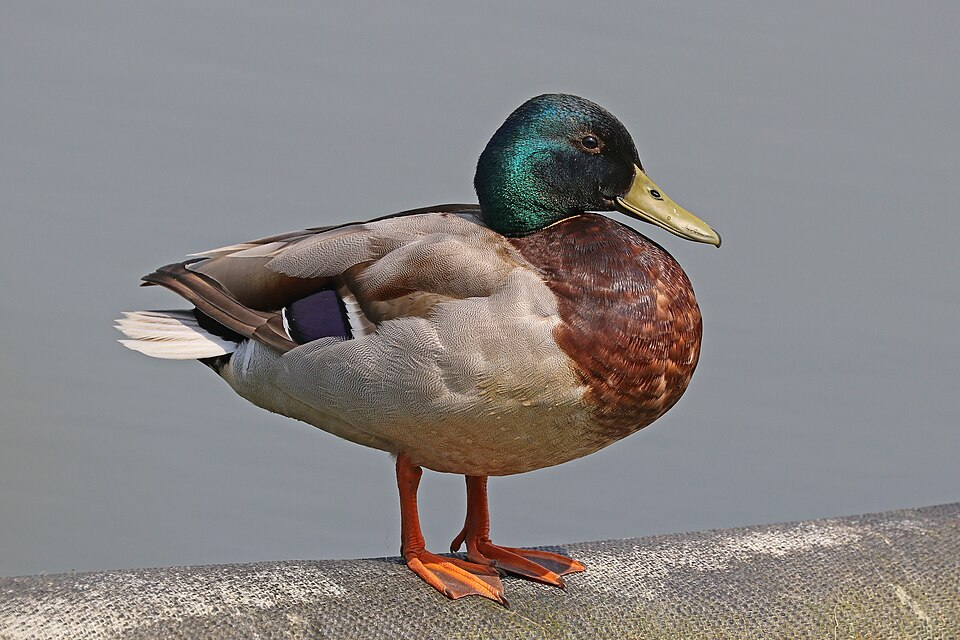 | 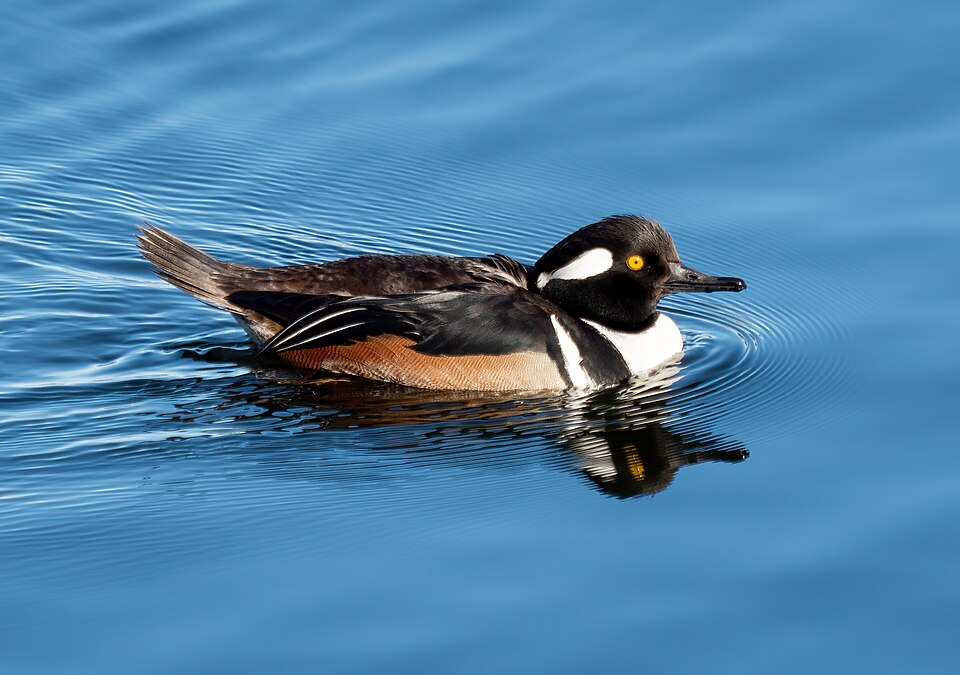 | 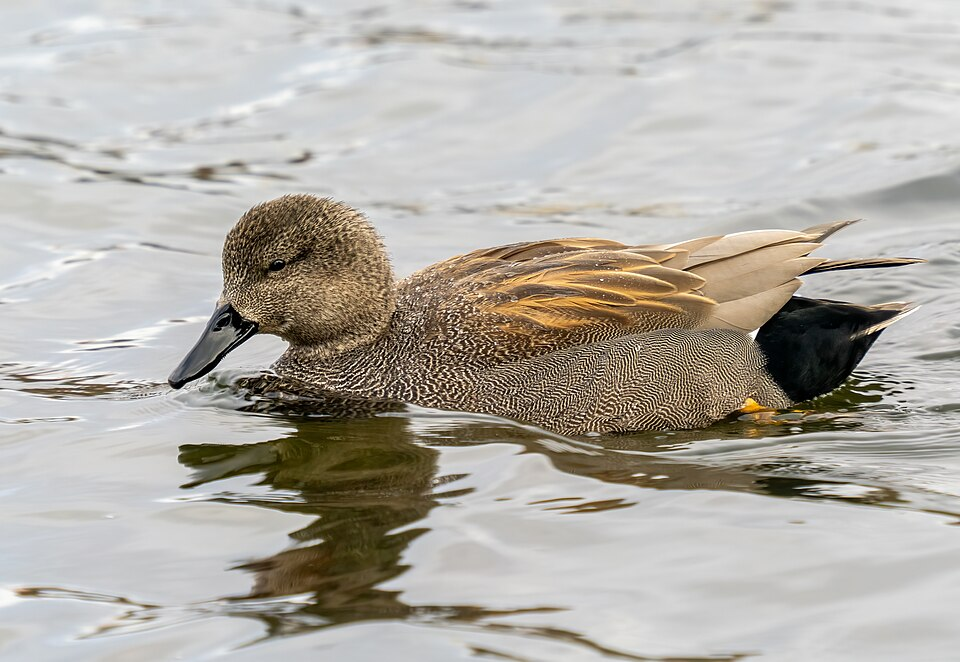 |
| *Anas platyrhynchos* | *Lophodytes cucullatus* | *Mareca strepera* |
| **Mallard:** 168 retained records. | **Hooded Merganser:** 71 retained records. | **Gadwall:** 29 retained records. |
| Photo: [Charles J. Sharp](https://commons.wikimedia.org/wiki/File:Mallard_duck_(Anas_platyrhynchos)_male.jpg) · [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0) | Photo: [Rhododendrites](https://commons.wikimedia.org/wiki/File:Hooded_merganser_male_in_CP_(40620).jpg) · [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0) | Photo: [Rhododendrites](https://commons.wikimedia.org/wiki/File:Gadwall_male_(00043).jpg) · [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0) |

Species portraits, not photographs of the analyzed Virginia records. These images show males; females and nonbreeding plumage can look different. [Photo sources and reuse licenses](images/species/README.md).


In [9]:
%%sql species_counts <<
SELECT common_name, scientific_name, species_code, count(*) AS records,
       count(DISTINCT observation_month) AS months_with_records
FROM virginia_ducks
GROUP BY ALL
ORDER BY records DESC, common_name;


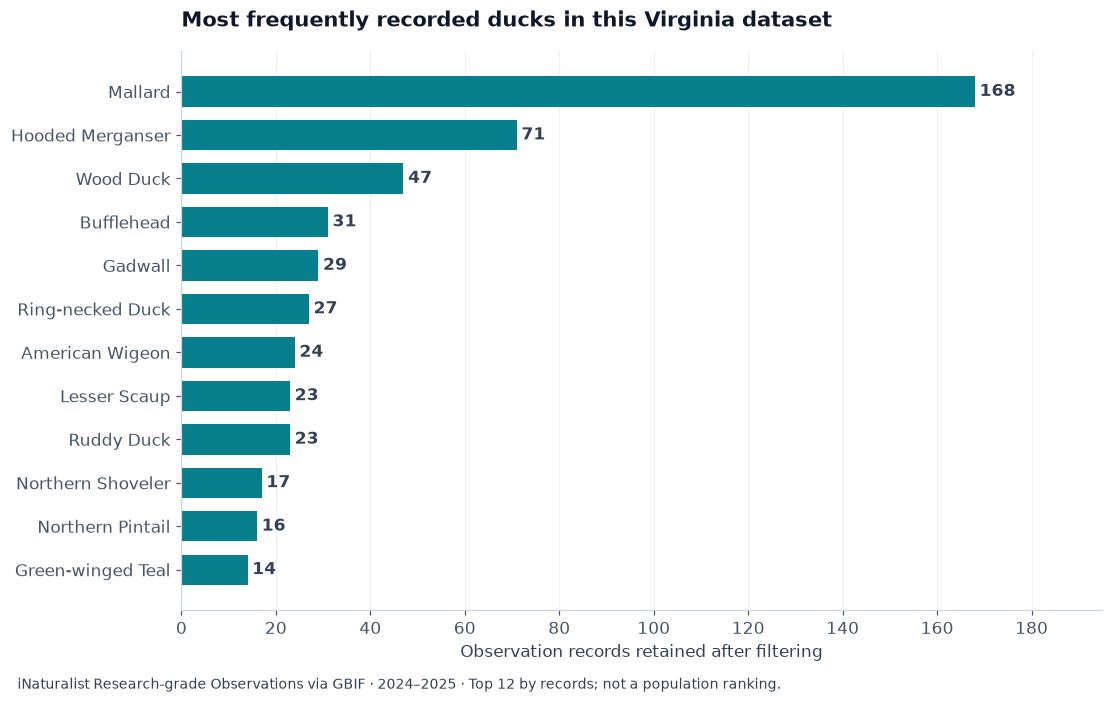

In [10]:
top = species_counts.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(10,6),layout="constrained")
ax.barh(top.common_name,top.records,color=TEAL,height=0.7)
for i,n in enumerate(top.records): ax.text(n+1,i,str(n),va="center",weight="bold",color=SLATE)
ax.set_xlim(0,top.records.max()*1.16)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_xlabel("Observation records retained after filtering")
ax.set_title("Most frequently recorded ducks in this Virginia dataset",loc="left",weight="bold",pad=16)
ax.grid(axis="x",alpha=0.6); ax.set_axisbelow(True)
fig.text(0.01,-0.035,"iNaturalist Research-grade Observations via GBIF · 2024–2025 · Top 12 by records; not a population ranking.",fontsize=9,color=SLATE)
save_chart(fig,"virginia-duck-species.png",notebook_dir)


## 3. How do the reported seasons differ?

We count records by species and calendar month across two complete years.
The heatmap compares each species with its own annual total: **color is the
percentage of that species' records in the month; cell numbers are record counts**.
A zero means no retained record in this dataset, not that the duck was absent.

These are descriptive reporting patterns. They do not control for observer
effort and must not be read as migration probabilities or arrival dates.


In [11]:
%%sql monthly <<
SELECT common_name, observation_month AS month, count(*) AS records
FROM virginia_ducks
GROUP BY common_name, observation_month
ORDER BY common_name, month;


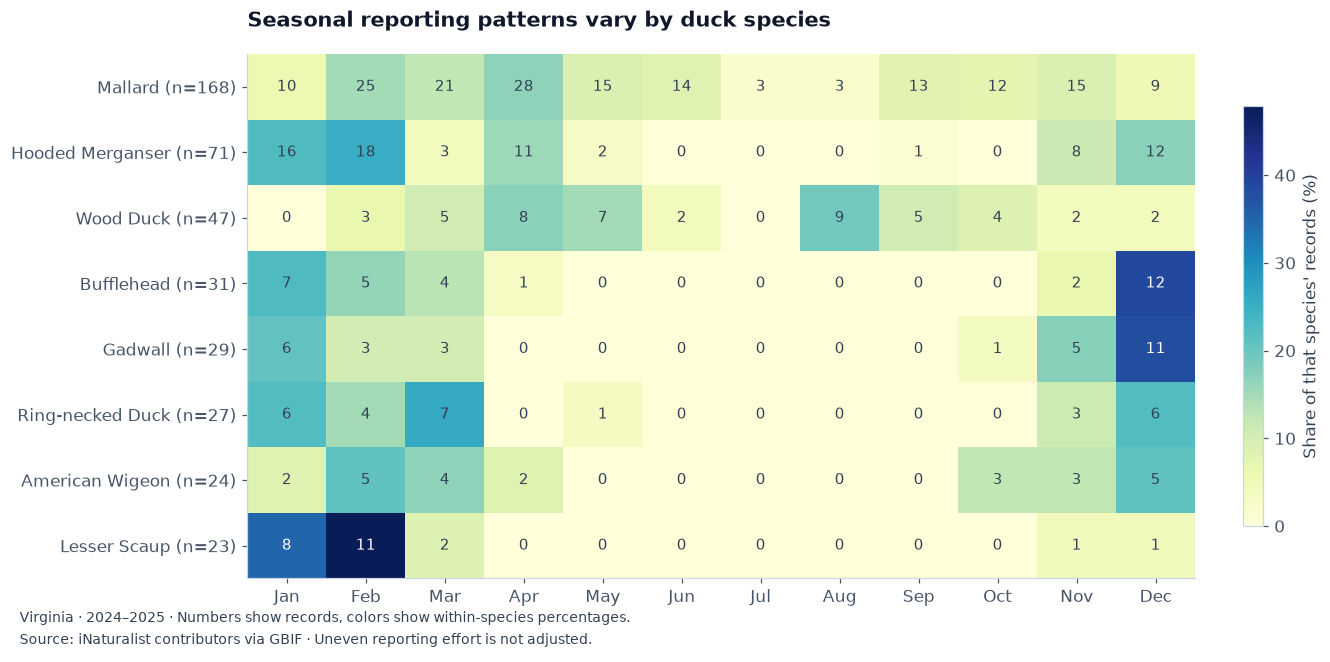

In [12]:
selected = species_counts.head(8)
counts = monthly.pivot(index="common_name",columns="month",values="records").reindex(
    index=selected.common_name,columns=range(1,13)).fillna(0)
shares = 100*counts.div(counts.sum(axis=1),axis=0)
fig, ax = plt.subplots(figsize=(12,5.5),layout="constrained")
im=ax.imshow(shares.values,cmap="YlGnBu",aspect="auto",vmin=0,vmax=max(35,shares.values.max()))
ax.set_xticks(range(12),["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_yticks(range(len(selected)),[f"{row.common_name} (n={row.records})" for row in selected.itertuples()])
for y in range(len(selected)):
    for x in range(12):
        n=int(counts.iloc[y,x])
        ax.text(x,y,str(n),ha="center",va="center",fontsize=10,
                color="white" if shares.iloc[y,x] > im.norm.vmax*0.55 else "#334155")
ax.set_title("Seasonal reporting patterns vary by duck species",loc="left",weight="bold",pad=18)
fig.colorbar(im,ax=ax,shrink=0.8,label="Share of that species' records (%)")
fig.text(0.01,-0.055,"Virginia · 2024–2025 · Numbers show records, colors show within-species percentages.\n"
         "Source: iNaturalist contributors via GBIF · Uneven reporting effort is not adjusted.",fontsize=9,color=SLATE,linespacing=1.6)
save_chart(fig,"virginia-duck-seasonality.png",notebook_dir)


## 4. Measure the modeled annual cycle inside Virginia

The observation heatmap measures reporting. The next chart uses Cornell's
**effort-standardized relative-abundance model**, queried through `vgi-ducks`.
Wood Duck, Bufflehead, and Blue-winged Teal show contrasting annual cycles.
All three selected 2023 products have a seasonal review quality of 3 in Cornell's
product configuration; this does not remove model uncertainty.

We simplify Overture's territorial boundary to a tolerance of 0.01 degrees
(roughly 1 km) before passing it as WKT to the worker. The worker selects native
**27 km Equal Earth grid cells whose centers fall inside that polygon**.
This is an equal-weight mean over modeled cells, not an exact area-weighted clip.
It is a statewide summary; small bays and individual ponds are below its resolution.

Relative abundance is the expected bird count on a standardized one-hour,
two-kilometer checklist under the model's observation conditions. The panels use
separate vertical scales. Missing cells are excluded, genuine zero remains zero,
and the lower panel reports modeled-cell coverage. These curves describe the
**2023 model year**, not the 2024–2025 observation snapshot above.


In [13]:
%%sql
CREATE TEMP TABLE model_region AS
SELECT ST_SimplifyPreserveTopology(geometry,0.01) AS geometry
FROM virginia WHERE is_territorial;
SET VARIABLE virginia_wkt = (SELECT ST_AsText(geometry) FROM model_region);
SELECT ST_NPoints(geometry) AS vertices, ST_IsValid(geometry) AS valid,
       round(ST_Area(ST_Transform(geometry,'OGC:CRS84','EPSG:26918',always_xy:=true))/1e6) AS area_km2
FROM model_region;


,vertices,valid,area_km2
0,181,True,110279.0


In [14]:
%%sql
CREATE TEMP TABLE weekly_models AS
SELECT 'Wood Duck' AS common_name, * FROM ducks.main.weekly_abundance(
  'wooduc', getvariable('virginia_wkt'), data_year:=2023, resolution:='27km')
UNION ALL
SELECT 'Bufflehead' AS common_name, * FROM ducks.main.weekly_abundance(
  'buffle', getvariable('virginia_wkt'), data_year:=2023, resolution:='27km')
UNION ALL
SELECT 'Blue-winged Teal' AS common_name, * FROM ducks.main.weekly_abundance(
  'buwtea', getvariable('virginia_wkt'), data_year:=2023, resolution:='27km');

SELECT common_name, count(*) AS weeks,
       min(selected_cell_count) AS selected_cells,
       round(min(coverage_fraction),3) AS minimum_coverage,
       round(max(coverage_fraction),3) AS maximum_coverage
FROM weekly_models GROUP BY common_name ORDER BY common_name;


,common_name,weeks,selected_cells,minimum_coverage,maximum_coverage
0,Blue-winged Teal,52,149,1.0,1.0
1,Bufflehead,52,149,1.0,1.0
2,Wood Duck,52,149,1.0,1.0


In [15]:
%%sql weekly <<
SELECT common_name, species_code, week_date::DATE AS week_date,
       mean_relative_abundance, max_relative_abundance,
       selected_cell_count, modeled_cell_count, coverage_fraction
FROM weekly_models ORDER BY common_name,week_date;


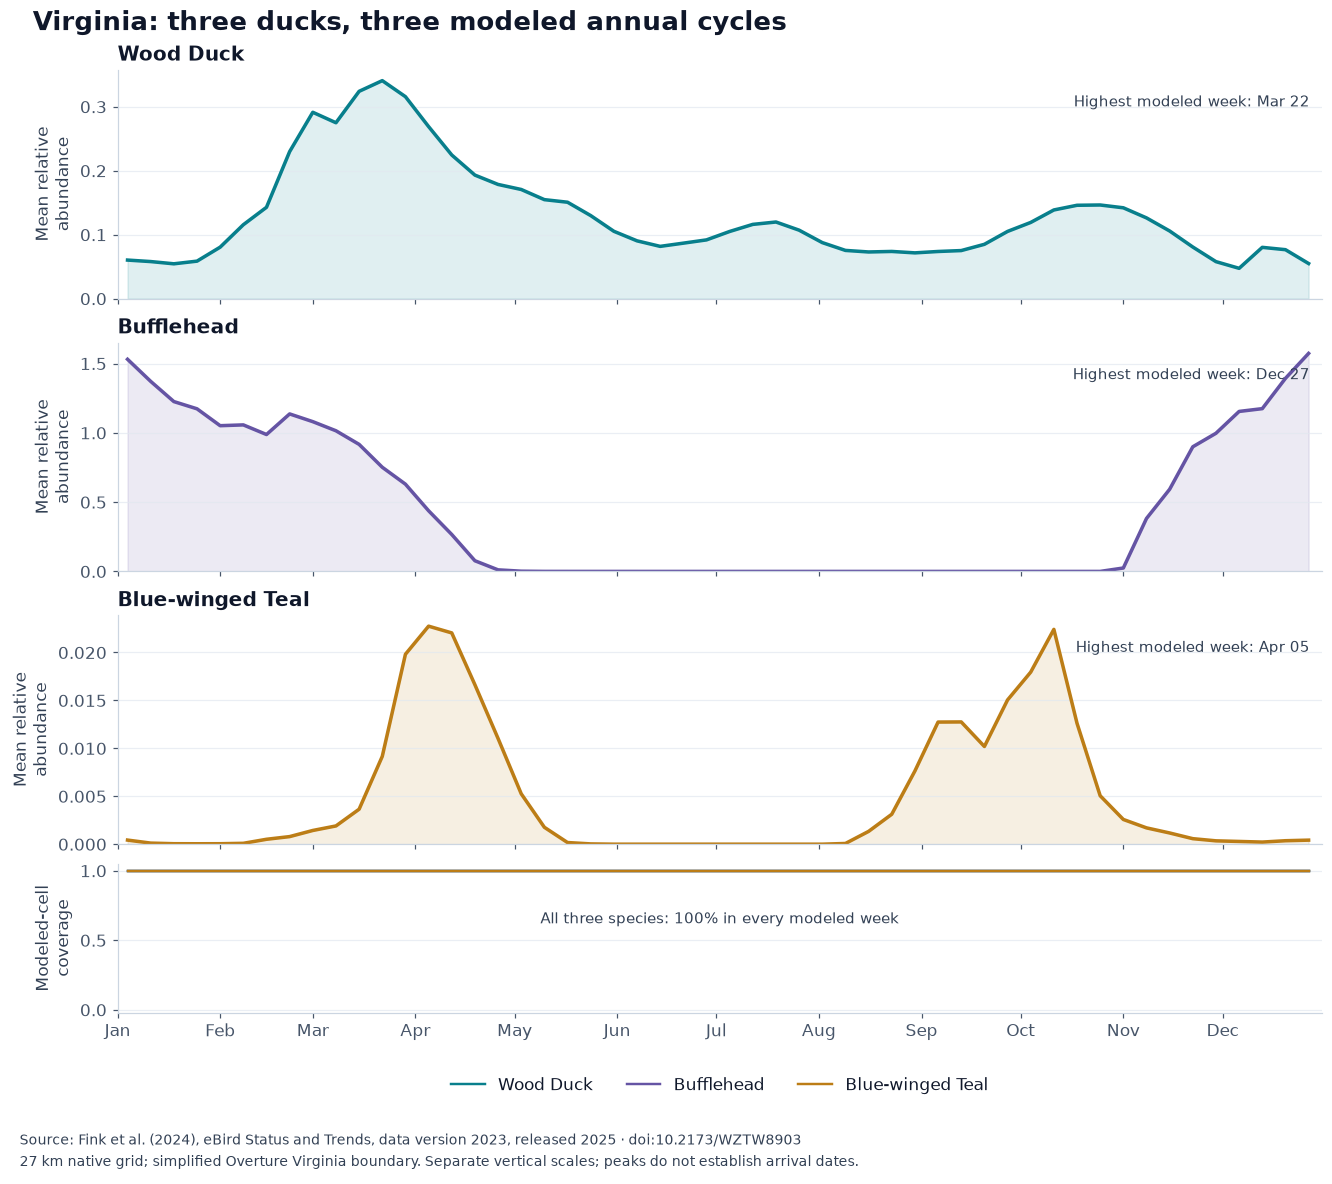

In [16]:
import matplotlib.dates as mdates
model_species=[('Wood Duck',TEAL),('Bufflehead','#6554a4'),('Blue-winged Teal',GOLD)]
fig,axes=plt.subplots(4,1,figsize=(12,10),sharex=True,layout="constrained",
                      gridspec_kw={'height_ratios':[1,1,1,0.65]})
for ax,(name,color) in zip(axes[:3],model_species):
    rows=weekly[weekly.common_name==name].sort_values('week_date')
    dates=pd.to_datetime(rows.week_date)
    ax.plot(dates,rows.mean_relative_abundance,color=color,linewidth=2.3)
    ax.fill_between(dates,0,rows.mean_relative_abundance,color=color,alpha=0.12)
    ax.set_title(name,loc='left',weight='bold',fontsize=13)
    ax.set_ylabel('Mean relative\nabundance');ax.set_ylim(bottom=0)
    ax.grid(axis='y',alpha=0.7)
    peak=rows.loc[rows.mean_relative_abundance.idxmax()]
    ax.text(0.99,0.84,f"Highest modeled week: {pd.Timestamp(peak.week_date):%b %d}",
            transform=ax.transAxes,ha='right',fontsize=10,color=SLATE)
    axes[3].plot(dates,rows.coverage_fraction,color=color,linewidth=1.6,label=name)
if weekly.coverage_fraction.eq(1).all():
    axes[3].text(0.5,0.6,'All three species: 100% in every modeled week',transform=axes[3].transAxes,ha='center',fontsize=10,color=SLATE)
axes[3].set_ylim(-0.02,1.05);axes[3].set_yticks([0,0.5,1])
axes[3].set_ylabel('Modeled-cell\ncoverage');axes[3].grid(axis='y',alpha=0.7)
axes[3].legend(loc='lower center',bbox_to_anchor=(0.5,-0.65),ncol=3,frameon=False)
axes[3].xaxis.set_major_locator(mdates.MonthLocator())
axes[3].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
axes[3].set_xlim(pd.Timestamp('2023-01-01'),pd.Timestamp('2023-12-31'))
fig.suptitle('Virginia: three ducks, three modeled annual cycles',x=0.02,ha='left',weight='bold',fontsize=17)
fig.text(0.01,-0.055,'Source: Fink et al. (2024), eBird Status and Trends, data version 2023, released 2025 · doi:10.2173/WZTW8903\n'
         '27 km native grid; simplified Overture Virginia boundary. Separate vertical scales; peaks do not establish arrival dates.',
         fontsize=9,color=SLATE,linespacing=1.6)
save_chart(fig,'virginia-ducks-migration.png',notebook_dir)


### What the curves reveal

**Bufflehead changes the most visibly across seasons:** its Virginia curve is
high in winter and close to zero through summer. **Blue-winged Teal has two
separate pulses**, with its highest modeled week on April 5 and another rise in
fall. **Wood Duck has a broader annual presence**, with a March 22 peak and
positive values through summer.

Those shapes are more useful than a single peak date: they distinguish seasonal
concentration from a broader annual presence. The three panels have different
vertical scales, so compare their timing and read the axes before comparing
magnitudes. Every selected cell has a modeled value in this run; the flat 100%
coverage line does not imply zero model uncertainty.


### Join seasonal range polygons to the state

A second spatial integration intersects each seasonal range with Overture's
Virginia boundary. The table measures the **percentage of Virginia's territory
intersected by each smoothed range**, not the percentage of birds or suitable
habitat. The 27 km range polygons are intentionally coarse.
Season dates describe Cornell's species-wide model seasons; they are not
Virginia-specific arrival and departure dates. Winter dates can wrap New Year.


In [17]:
%%sql
CREATE TEMP TABLE seasonal_models AS
SELECT * FROM ducks.main.seasonal_ranges('wooduc',data_year:=2023,resolution:='27km')
UNION ALL
SELECT * FROM ducks.main.seasonal_ranges('buffle',data_year:=2023,resolution:='27km')
UNION ALL
SELECT * FROM ducks.main.seasonal_ranges('buwtea',data_year:=2023,resolution:='27km');

SELECT r.common_name, r.season, r.start_date, r.end_date, r.wraps_year,
       round(100 * ST_Area(ST_Transform(
         ST_Intersection(ST_GeomFromWKB(r.geometry_wkb),v.geometry),
         'OGC:CRS84','EPSG:26918',always_xy:=true)) /
         ST_Area(ST_Transform(v.geometry,'OGC:CRS84','EPSG:26918',always_xy:=true)),1)
         AS virginia_territory_percent
FROM seasonal_models r CROSS JOIN virginia v
WHERE v.is_territorial
ORDER BY r.common_name,r.season;


,common_name,season,start_date,end_date,wraps_year,virginia_territory_percent
0,Blue-winged Teal,breeding,2023-06-14,2023-07-12,False,0.0
1,Blue-winged Teal,nonbreeding,2023-12-27,2023-01-25,True,1.2
2,Blue-winged Teal,postbreeding_migration,2023-07-19,2023-12-20,False,64.4
3,Blue-winged Teal,prebreeding_migration,2023-02-01,2023-06-07,False,75.7
4,Bufflehead,breeding,2023-06-07,2023-07-19,False,0.8
5,Bufflehead,nonbreeding,2023-12-27,2023-02-15,True,64.0
6,Bufflehead,postbreeding_migration,2023-07-26,2023-12-20,False,87.8
7,Bufflehead,prebreeding_migration,2023-02-22,2023-05-31,False,77.3
8,Wood Duck,breeding,2023-04-26,2023-06-21,False,96.4
9,Wood Duck,nonbreeding,2023-12-06,2023-01-25,True,86.0


## 5. Put the duck records beside mapped water

Overture adds context that the bird records do not contain. We inspect three
bounded windows: **Northern Virginia, Richmond, and Hampton Roads**. The query
below retains overlapping water polygons, including coastal water, and excludes
swimming pools, drains, and wastewater features.

These are mapped water features, **not a habitat-suitability or public-access map**.
Some wetlands and seasonal water are missing. Water boundaries come from the
2026 Overture release, while the observations are from 2024–2025.


In [18]:
%%sql
CREATE TEMP TABLE focus_regions(name, west, south, east, north) AS VALUES
  ('Northern Virginia',-77.4,38.55,-76.95,39.05),
  ('Richmond',-77.65,37.35,-77.2,37.7),
  ('Hampton Roads',-76.5,36.55,-75.85,37.15);


,Success


In [19]:
%%sql
CREATE TEMP TABLE local_water AS
SELECT 'Northern Virginia' AS focus, id, names.primary AS name, subtype, class, geometry
FROM overture.base.water
WHERE bbox.xmin <= -76.95 AND bbox.xmax >= -77.4
  AND bbox.ymin <= 39.05 AND bbox.ymax >= 38.55
  AND ST_GeometryType(geometry) IN ('POLYGON','MULTIPOLYGON')
  AND (subtype IN ('lake','pond','river','stream','ocean')
       OR (subtype='water' AND class='water')
       OR (subtype='reservoir' AND class='reservoir'));


,Success


In [20]:
# Apply exactly the same bounded query to the other two displayed windows.
for label,west,south,east,north in [
    ("Richmond",-77.65,37.35,-77.2,37.7),
    ("Hampton Roads",-76.5,36.55,-75.85,37.15),
]:
    session.exec_driver_sql(f"""INSERT INTO local_water
    SELECT {quote(label)},id,names.primary,subtype,class,geometry
    FROM overture.base.water
    WHERE bbox.xmin <= {east} AND bbox.xmax >= {west}
      AND bbox.ymin <= {north} AND bbox.ymax >= {south}
      AND ST_GeometryType(geometry) IN ('POLYGON','MULTIPOLYGON')
      AND (subtype IN ('lake','pond','river','stream','ocean')
           OR (subtype='water' AND class='water')
           OR (subtype='reservoir' AND class='reservoir'))""")
session.commit()


### Ask a spatial question, with distances in meters

For each window, we test whether each record lies within **500 m** of at least
one selected water polygon. We project the geometries into UTM zone 18N for this
local distance calculation. `EXISTS` keeps one row per observation even when
several water features overlap.

Coordinate uncertainty is up to 250 m, so this is an approximate contextual
comparison. A record near water does not prove habitat use; a record outside the
buffer does not prove the absence of water.


In [21]:
%%sql
CREATE TEMP TABLE water_m AS
SELECT *, ST_Transform(geometry,'OGC:CRS84','EPSG:26918',always_xy:=true) AS geom_m
FROM local_water;

CREATE TEMP TABLE focus_records AS
SELECT f.name AS focus, r.*,
       ST_Transform(r.point,'OGC:CRS84','EPSG:26918',always_xy:=true) AS point_m
FROM virginia_ducks AS r JOIN focus_regions AS f
  ON r.longitude BETWEEN f.west AND f.east
 AND r.latitude BETWEEN f.south AND f.north;

CREATE TEMP TABLE water_context AS
SELECT r.*, EXISTS (
  SELECT 1 FROM water_m AS w
  WHERE w.focus=r.focus AND ST_DWithin(w.geom_m,r.point_m,500)
) AS within_500m_of_mapped_water
FROM focus_records AS r;

SELECT focus, count(*) AS records, count(DISTINCT species_code) AS duck_species,
       count(*) FILTER (WHERE within_500m_of_mapped_water) AS records_near_water
FROM water_context GROUP BY focus ORDER BY focus;


,focus,records,duck_species,records_near_water
0,Hampton Roads,64,15,62
1,Northern Virginia,206,19,183
2,Richmond,29,13,28


In [22]:
%%sql water_shapes <<
SELECT w.focus,
       ST_AsGeoJSON(ST_SimplifyPreserveTopology(ST_Intersection(w.geometry,
         ST_MakeEnvelope(f.west,f.south,f.east,f.north)),0.0001)) AS geometry_json
FROM local_water AS w JOIN focus_regions AS f ON w.focus=f.name;


In [23]:
%%sql focused_points <<
SELECT focus,longitude,latitude,common_name,within_500m_of_mapped_water
FROM water_context ORDER BY focus,gbif_id;


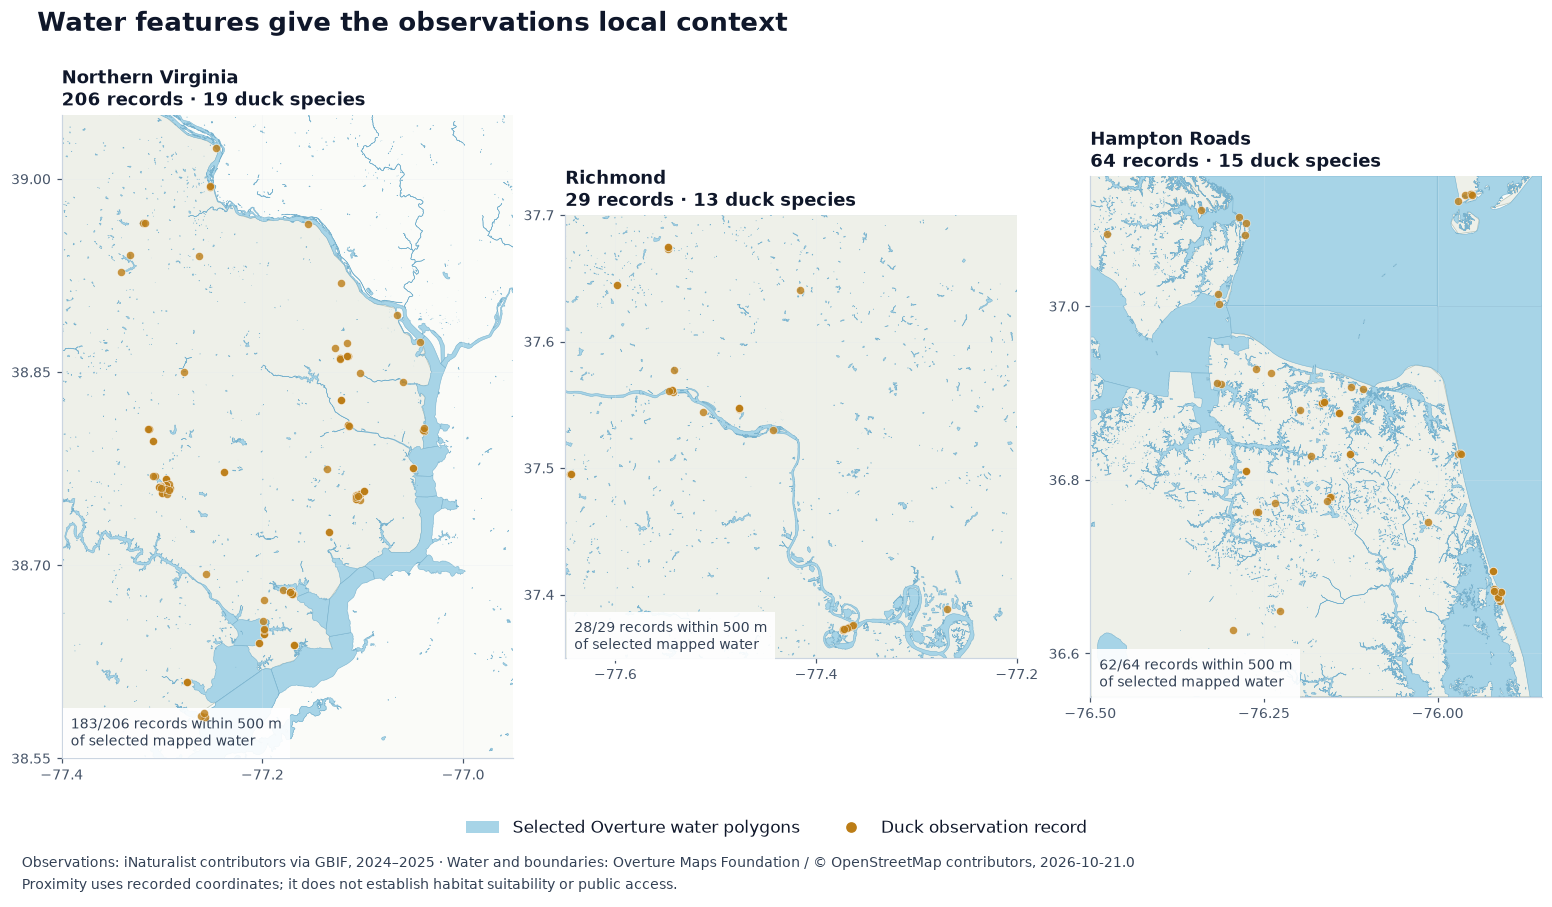

In [24]:
focus_bounds=[("Northern Virginia",-77.4,38.55,-76.95,39.05),
              ("Richmond",-77.65,37.35,-77.2,37.7),
              ("Hampton Roads",-76.5,36.55,-75.85,37.15)]
fig,axes=plt.subplots(1,3,figsize=(14,7.5),layout="constrained")
for ax,(label,west,south,east,north) in zip(axes,focus_bounds):
    ax.set_facecolor("#fafbf8")
    draw_geometry(ax,land,"#eef0e9","#bbc6bb",linewidth=0.5)
    for geom in water_shapes.loc[water_shapes.focus==label,"geometry_json"]:
        draw_geometry(ax,geom,"#a7d4e7","#78b2ce",linewidth=0.35)
    rows=focused_points[focused_points.focus==label]
    ax.scatter(rows.longitude,rows.latitude,s=28,color=GOLD,alpha=0.8,
               edgecolor="white",linewidth=0.35,zorder=5)
    ax.set_xlim(west,east);ax.set_ylim(south,north)
    ax.set_aspect(1/np.cos(np.deg2rad((south+north)/2)))
    ax.xaxis.set_major_locator(plt.MaxNLocator(3));ax.yaxis.set_major_locator(plt.MaxNLocator(4))
    ax.tick_params(labelsize=9)
    ax.grid(alpha=0.35,linewidth=0.4)
    ax.set_title(f"{label}\n{len(rows)} records · {rows.common_name.nunique()} duck species",loc="left",fontsize=12,weight="bold")
    near=int(rows.within_500m_of_mapped_water.sum())
    ax.text(0.02,0.02,f"{near}/{len(rows)} records within 500 m\nof selected mapped water",
            transform=ax.transAxes,fontsize=9,color=SLATE,
            bbox={"facecolor":"white","alpha":0.92,"edgecolor":"none","pad":5})
fig.suptitle("Water features give the observations local context",fontsize=17,weight="bold",x=0.02,ha="left")
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
fig.legend(handles=[Patch(facecolor="#a7d4e7",label="Selected Overture water polygons"),
                    Line2D([0],[0],marker="o",linestyle="none",color=GOLD,label="Duck observation record")],
           loc="lower center",bbox_to_anchor=(0.5,-0.025),ncol=2,frameon=False)
fig.text(0.01,-0.07,"Observations: iNaturalist contributors via GBIF, 2024–2025 · Water and boundaries: Overture Maps Foundation / © OpenStreetMap contributors, 2026-10-21.0\n"
         "Proximity uses recorded coordinates; it does not establish habitat suitability or public access.",fontsize=9,color=SLATE,linespacing=1.6)
save_chart(fig,"virginia-ducks-water.png",notebook_dir)


### Connect records to named water features

This final join lists named features with nearby records in the three windows.
A record can appear near more than one named feature, so these counts must not be
summed to obtain a total. They describe spatial proximity, not visitor access or
confirmed use of a particular water body.


In [25]:
%%sql
SELECT w.focus, w.name AS water_feature,
       count(DISTINCT r.gbif_id) AS nearby_records,
       count(DISTINCT r.species_code) AS duck_species
FROM water_m AS w JOIN focus_records AS r
  ON w.focus=r.focus AND ST_DWithin(w.geom_m,r.point_m,500)
WHERE w.name IS NOT NULL
GROUP BY w.focus,w.name
ORDER BY nearby_records DESC,w.focus,water_feature
LIMIT 10;


,focus,water_feature,nearby_records,duck_species
0,Northern Virginia,Burke Lake,38,14
1,Northern Virginia,Pohick Bay,18,10
2,Hampton Roads,Lake Smith,8,5
3,Northern Virginia,Belmont Bay,8,5
4,Northern Virginia,Cameron Run,6,3
5,Northern Virginia,Sparrow Pond,5,1
6,Hampton Roads,Lake Lawson,4,3
7,Hampton Roads,Lake Rudee,4,3
8,Hampton Roads,Lake Wesley,4,3
9,Hampton Roads,Rudee Inlet,4,3


### From a coordinate to a recognizable place

**Burke Lake leads this table with 38 nearby records and 14 duck species.**
Pohick Bay follows with 18 records and 10 species. The join turns scattered
observation coordinates into a comparison of named water features that a reader
can recognize. It is also easy to audit: the visible SQL shows the 500 m distance,
the species counts, and how duplicate matches are handled.

These results apply to the filtered source and the three chosen map windows.
They describe nearby reports, not the number of birds living on each lake or bay.


In [26]:
assert len(boundary_shapes)==2 and boundary_shapes.is_territorial.sum()==1
assert points.gbif_id.is_unique and len(points)>0
assert set(points.observation_year).issubset({2024,2025})
assert points.uncertainty_m.between(0,250).all()
assert species_counts.records.sum()==len(points)
assert monthly.records.sum()==len(points)
assert focused_points.groupby('focus').size().min()>0
assert set(water_shapes.focus)=={'Northern Virginia','Richmond','Hampton Roads'}
assert not points.scientific_name.str.contains('Branta|Cygnus|Anser',regex=True).any()
qa=session.exec_driver_sql("""SELECT count(*) FROM virginia_ducks r
WHERE NOT EXISTS(SELECT 1 FROM virginia v WHERE v.is_territorial AND ST_Covers(v.geometry,r.point))""").scalar()
assert qa==0
assert len(weekly)==156 and weekly.groupby('species_code').size().eq(52).all()
assert not weekly.duplicated(['species_code','week_date']).any()
assert weekly.coverage_fraction.between(0,1).all()
assert (weekly.modeled_cell_count<=weekly.selected_cell_count).all()
assert weekly.mean_relative_abundance.dropna().ge(0).all()
assert session.exec_driver_sql("SELECT bool_and(ST_IsValid(ST_GeomFromWKB(geometry_wkb))) FROM seasonal_models").scalar()
assert session.exec_driver_sql("SELECT count(*) FROM seasonal_models").scalar()==12
peaks=weekly.loc[weekly.groupby('species_code').mean_relative_abundance.idxmax(),
    ['common_name','week_date','mean_relative_abundance','coverage_fraction']].copy()
peaks['week_date']=peaks.week_date.astype(str)
provenance={**observation_manifest,'overture_release':OVERTURE_RELEASE,'overture_worker_commit':overture_commit,
            'duck_worker_release':'v0.1.0','duck_records_inside_virginia':len(points),
            'duck_species':points.species_code.nunique(),'duckdb_version':duckdb.__version__, 'status_model_year':2023,
            'status_resolution_km':27, 'status_species':['wooduc','buffle','buwtea'],
            'status_weekly_rows':len(weekly), 'status_peak_weeks':peaks.to_dict(orient='records'),
            'executed_at':datetime.now().astimezone().isoformat()}
(project_dir/'.cache/virginia-ducks/verification.json').write_text(json.dumps(provenance,indent=2,default=int)+'\n')
%sql --close virginia_demo
engine.dispose();extension_directory.cleanup()
print('Verified unique records, species and month totals, Virginia containment, and all three water windows.')


Verified unique records, species and month totals, Virginia containment, and all three water windows.


## What this notebook establishes

It shows actual public duck observations in Virginia and demonstrates how the two
VGI workers can join species data to geographic features. It does not estimate
population size, identify arrival dates, or recommend access to private land.
The eBird model adds effort-standardized annual cycles and range polygons.
A local peak can reflect breeding or winter residence, not a migration event.
Coverage is the share of selected grid centers with modeled values; it is not
an uncertainty interval or the fraction of Virginia's area modeled.

**Sources and scope**

- [Species photograph credits](images/species/README.md): six real photographs with photographer, source-page, and license links. The images retain their individual Creative Commons licenses; all are embedded for portable viewing.

- Fink et al. (2024), [eBird Status and Trends, data version 2023, released 2025](https://doi.org/10.2173/WZTW8903), Cornell Lab of Ornithology. [Product methods and interpretation](https://ebird.github.io/ebirdst/articles/status.html). These derived charts use authenticated products; no key or source raster is included in the repository. [Status and Trends](https://science.ebird.org/en/status-and-trends) data retain Cornell's terms.

- [iNaturalist Research-grade Observations via GBIF](https://doi.org/10.15468/ab3s5x), contributed by iNaturalist observers. The query retains only records with CC0 or CC BY licenses; licenses and original record links remain in the local data cache. The species portraits come from separately credited Wikimedia Commons photographs, not these observation records.
- [GBIF occurrence API](https://techdocs.gbif.org/en/openapi/v1/occurrence): all pages of the bounded 2024–2025 Virginia query are retrieved. This is a selected source, not an exhaustive bird inventory.
- [Overture divisions](https://docs.overturemaps.org/guides/divisions/) and [water](https://docs.overturemaps.org/schema/reference/base/water/), release **2026-10-21.0**. Water features derive from OpenStreetMap contributors. Source data retain their upstream licenses; see [Overture attribution](https://docs.overturemaps.org/attribution/).
- [Duck taxonomy scope](../data/README.md): extant exact scientific-name matches to the worker's eBird 2026 duck catalog. Unmatched names, geese, and swans are excluded.

The local cache records the exact API filters, retrieval time, and SHA256. Refreshes
can change counts as GBIF receives new records or corrections. The saved charts
are a snapshot of the recorded execution. The executable notebook preserves the
setup; the reader edition omits it for GitHub.
